In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sb
!pip install catboost
!pip install xgboost
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import AdaBoostClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier
from catboost import CatBoostClassifier,CatBoostRegressor
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.model_selection import train_test_split, KFold, cross_val_score, GridSearchCV

from sklearn.model_selection import ShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, balanced_accuracy_score, roc_auc_score, confusion_matrix, classification_report
from sklearn.metrics import precision_score, recall_score, f1_score, matthews_corrcoef, cohen_kappa_score
from sklearn.metrics import roc_curve, auc, roc_auc_score
from sklearn.model_selection import cross_val_predict
import warnings
import time
warnings.filterwarnings("ignore")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 98.7/98.7 MB 20.7 MB/s eta 0:00:00


# data preparation

In [2]:
def prepare_target_feature(unitig_file_path, metadata_file_path, target_column):
    """
    Prepares the target and feature datasets for a given antibiotic resistance data.

    Parameters:
    - unitig_file_path: Path to the unitig file (sequence data)
    - metadata_file_path: Path to the metadata file
    - target_column: The target column in the metadata file (e.g., 'cip_sr')

    Returns:
    - X: The feature dataset (aligned sequence data)
    - y: The target dataset (binary)
    """
    # Load the sequence (unitig) data
    sequence_data = pd.read_csv(unitig_file_path, sep=" ", index_col=0, low_memory=False)
    # Transpose the sequence data
    sequence_data_transposed = sequence_data.transpose()
    # Load the metadata
    metadata = pd.read_csv(metadata_file_path, index_col=0)
    # Drop rows with null values in the target column
    cleaned_metadata = metadata.dropna(subset=[target_column])
    # Convert the target column to binary: Sensitive=0, Resistant=1
    cleaned_metadata[f'{target_column}_binary'] = cleaned_metadata[target_column].map({'Sensitive': 0, 'Resistant': 1})
    # Keep only the binary target column
    target_data = cleaned_metadata[[f'{target_column}_binary']]
    # Align the sequence data index with the target dataset index
    aligned_sequence_data = sequence_data_transposed[sequence_data_transposed.index.isin(target_data.index)]
    # Align the target data index with the sequence dataset index
    aligned_target_data = target_data[target_data.index.isin(aligned_sequence_data.index)]
    # Convert the target data to a Series
    target = aligned_target_data.squeeze()
    # The feature dataset is the aligned sequence data
    feature = aligned_sequence_data
    return target, feature, cleaned_metadata

In [48]:
target, feature, cleaned_metadata = prepare_target_feature('/content/cip_sr_gwas_filtered_unitigs.Rtab', '/content/metadata_remane_original.csv', 'cip_sr')

In [4]:
print(feature.shape)
print(feature.tail(5))
print(target.shape)
print(target.tail(5))

(3313, 8873)
pattern_id  ACGTTTATGCCGTTATCGATCCGATAGCCGGT  \
SRR5827366                                 0   
SRR5827371                                 0   
SRR5827372                                 0   
SRR5827369                                 0   
SRR5827370                                 0   

pattern_id  CATCTGCACCCTGTCGGCACTCGCCGCCTGAACCACCCCGTCCGGACAAGG  \
SRR5827366                                                  0     
SRR5827371                                                  0     
SRR5827372                                                  0     
SRR5827369                                                  0     
SRR5827370                                                  0     

pattern_id  CACAAAACTCGTTTCCTGCTCCGAAATGGGCGA,GTAAGGGCTTTCTTAAATTTGATTAAAGGTCGTCTGAA,AACCGAAACCGACCGCGCCGTCGAATATCAGGCGGTCGCACCGGAAGTACG  \
SRR5827366                                                  0                                                                              
SRR5827371     

In [5]:
feature.shape

(3313, 8873)

In [6]:
feature.head(5)

pattern_id,ACGTTTATGCCGTTATCGATCCGATAGCCGGT,CATCTGCACCCTGTCGGCACTCGCCGCCTGAACCACCCCGTCCGGACAAGG,"CACAAAACTCGTTTCCTGCTCCGAAATGGGCGA,GTAAGGGCTTTCTTAAATTTGATTAAAGGTCGTCTGAA,AACCGAAACCGACCGCGCCGTCGAATATCAGGCGGTCGCACCGGAAGTACG",AAATCTTCCGCTTTAATCCATTTGCCGTCCGA,"AAACCTGCCGCAGCCGGCGCATCTTTGGGCGGCGGTCTGGAC,AACGTGGTGTACCAAACCCGCCGTTTCGACCGTTATAAAGAA",CCCAACACACTCGACGTATGGATGAGCCACGGC,TTTTCAACAAAAAACTGCTTGTCCAACGGCAAA,TTTCAACCGGATAGCTGAAAAAACAAAAAAGTTCGATA,CATCACTTCCCGCTGCCGTTTTTTTGTTTCAGACGGCAT,"AAACTGCTTGTCCAACGGCAAACCGGCGGGCAGG,CACATAGAAAAGCGGAACAAGGAACACGGATAAAAGCGT,TTTCCTCCGACCATACAGAAGATACCATACGCCTCTCCAAACGTATGG,AGAAAGTGGAATTGAGGAAACCTTTTTATCCGATGAG,TGGATATAGTCTTTTAATTCGTCTTTCGTCGCCCAAGCAGTGCCATAA",...,CGCCTATGTGCTGCAACTTTTGGACACCGCGCTCGC,GGAATCAGGACGATAAACAAAATGCTGCCGGCGAG,CGCTACATAAGGAGAACCCTAAAATGCCGCA,ACATCCTGCCATCCGACAAGCGGCGGCAACCGCCAAAAAC,TCTTGGGCGCCGTTTGTGGGTTTGTTTATCGCGCG,AAGCAGCGCACGCTGTGAATCACATCTTTCGCC,ACCGCGCCGGACAGGGTGCGCGTAAACGGCAGTTG,AACGACAATACACACACCCTTCCCCCGCGCC,AAATTCATCAAAGAGCAAAGCGATTGGAAACCTCTGCCTGCTAATGCCGGTGAGTTGACCC,"GCCGCCTTGTCCTGATTTTTGTTAATCCGCCA,AACCATAAGTCGGCAACTTCGTAAACCAGGTGGGACGGGTCTTTGTCTTTGGATGC,AGAAGCTCGGAATCGTTCAGCAATACGCCTGCG"
11791_8#10,0,0,0,0,0,0,0,0,0,0,...,1,1,1,1,1,1,1,1,1,1
11791_8#11,0,0,0,0,0,0,0,0,0,0,...,1,1,1,1,1,1,1,1,1,1
11791_8#12,0,0,0,0,0,0,0,0,0,0,...,1,1,1,1,1,1,1,1,1,1
11791_8#13,0,0,0,0,0,0,0,0,0,0,...,1,1,1,1,1,1,1,1,1,1
11791_8#14,0,0,0,0,0,0,0,0,0,0,...,1,1,1,1,1,1,1,1,1,1


In [7]:
target.shape

(3313,)

In [8]:
target.value_counts()

,count
cip_sr_binary,
0,1695
1,1618


In [ ]:
feature.to_csv("transformed_cipro_feature.csv")

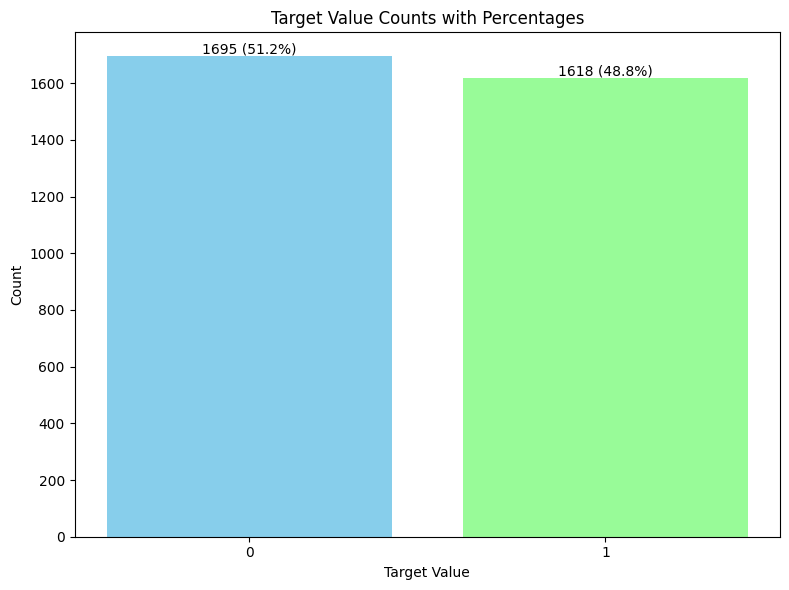

In [9]:
value_counts = target.value_counts()
total = len(target)
colors = ['#87CEEB', '#98FB98']

# Create a bar plot with different colors for each bar
plt.figure(figsize=(8, 6))
bars = plt.bar(value_counts.index.astype(str), value_counts.values, color=colors)

# Add the count and percentage on top of each bar
for bar in bars:
    yval = bar.get_height()
    percentage = (yval / total) * 100
    plt.text(bar.get_x() + bar.get_width() / 2, yval + 0.5, f'{int(yval)} ({percentage:.1f}%)',
             ha='center', va='bottom')

# Add labels and title
plt.xlabel('Target Value')
plt.ylabel('Count')
plt.title('Target Value Counts with Percentages')
plt.tight_layout()

# Show the plot
plt.show()

In [10]:
# Global arrays to store ML scores
ml_k_fold_scores = []
ml_average_scores = []

# calculation metrix of all fold

In [11]:
def calculate_metrics(y_test, y_pred, model_name, fold, y_pred_prob=None):
    metrics = {
        'model': model_name,
        'fold': fold + 1,
        'accuracy': accuracy_score(y_test, y_pred),
        'balanced_accuracy': balanced_accuracy_score(y_test, y_pred),
        'precision': precision_score(y_test, y_pred),
        'recall': recall_score(y_test, y_pred),
        'f1_score': f1_score(y_test, y_pred),
        'mcc': matthews_corrcoef(y_test, y_pred),
        'kappa': cohen_kappa_score(y_test, y_pred),
        'confusion_matrix': confusion_matrix(y_test, y_pred),
        'classification_report': classification_report(y_test, y_pred, output_dict=True)
    }

    # AUC-ROC is only calculated if probability predictions are available
    if y_pred_prob is not None:
        metrics['auc_roc'] = roc_auc_score(y_test, y_pred_prob)

    # Append metrics to global ml_k_fold_scores
    ml_k_fold_scores.append(metrics)

# Fit model function

In [13]:
# Function to evaluate ML models using KFold and store in global variables
def evaluate_ml_model(feature, target, models, k=5):

    kfold = KFold(n_splits=k, shuffle=True, random_state=42)

    for model_name, estimator in models.items():
        print(f"\nEvaluating model: {model_name}")
        balance_accuracies = []

        for fold, (train_index, test_index) in enumerate(kfold.split(feature, target)):
            # Split the data
            X_train, X_test = feature.iloc[train_index], feature.iloc[test_index]
            y_train, y_test = target.iloc[train_index], target.iloc[test_index]

            # Train the model
            estimator.fit(X_train, y_train)

            # Predict on the test set
            y_pred = estimator.predict(X_test)

            # If the model supports probabilities, get probability predictions for ROC-AUC
            y_pred_prob = None
            if hasattr(estimator, "predict_proba"):
                y_pred_prob = estimator.predict_proba(X_test)[:, 1]

            # Calculate all metrics and store in global ml_k_fold_scores
            calculate_metrics(y_test, y_pred, model_name, fold, y_pred_prob)

            # Collect accuracy for average calculation
            balance_accuracies.append(balanced_accuracy_score(y_test, y_pred))

        # Calculate average accuracy across folds and store in global ml_average_scores
        avg_balance_accuracies = np.mean(balance_accuracies)
        ml_average_scores.append({
            'model': model_name,
            'average_balance_accuracy': avg_balance_accuracies
        })

        print(f'Average balance Accuracy for {model_name}: {avg_balance_accuracies:.4f}')

# ML models

In [14]:
# ML Model
models = {
    'CatBoost': CatBoostClassifier(task_type='GPU', iterations=500, verbose=0),
    'RandomForest': RandomForestClassifier(),
    'XGB': XGBClassifier(use_label_encoder=False, eval_metric='logloss'),
    'LDA': LinearDiscriminantAnalysis(),
    'KNN': KNeighborsClassifier(),
    'GaussianNB': GaussianNB(),
    'SVC': SVC(class_weight='balanced'),
    'DecisionTree': DecisionTreeClassifier(),
    'GradientBoosting': GradientBoostingClassifier()
}



In [15]:
# Assuming `feature` and `target` are your input features and labels
# k-fold model evaluation
evaluate_ml_model(feature, target, models)


Evaluating model: CatBoost
Average balance Accuracy for CatBoost: 0.9810

Evaluating model: RandomForest
Average balance Accuracy for RandomForest: 0.9745

Evaluating model: XGB
Average balance Accuracy for XGB: 0.9814

Evaluating model: LDA
Average balance Accuracy for LDA: 0.7278

Evaluating model: KNN
Average balance Accuracy for KNN: 0.9682

Evaluating model: GaussianNB
Average balance Accuracy for GaussianNB: 0.9254

Evaluating model: SVC
Average balance Accuracy for SVC: 0.9713

Evaluating model: DecisionTree
Average balance Accuracy for DecisionTree: 0.9674

Evaluating model: GradientBoosting
Average balance Accuracy for GradientBoosting: 0.9749


In [18]:

df_ml_k_fold_scores=pd.DataFrame(ml_k_fold_scores)
df_ml_k_fold_scores.to_excel('cip_ml_k_fold_scores.xlsx', index=False)
print(df_ml_k_fold_scores)

               model  fold  accuracy  balanced_accuracy  precision    recall  \
0           CatBoost     1  0.975867           0.974838   0.986622  0.960912   
1           CatBoost     2  0.986425           0.986521   0.991071  0.982301   
2           CatBoost     3  0.972851           0.972564   0.984177  0.959877   
3           CatBoost     4  0.986405           0.986239   0.990536  0.981250   
4           CatBoost     5  0.984894           0.984811   0.993789  0.975610   
5       RandomForest     1  0.971342           0.970400   0.980000  0.957655   
6       RandomForest     2  0.974359           0.974448   0.979167  0.970501   
7       RandomForest     3  0.968326           0.967729   0.993485  0.941358   
8       RandomForest     4  0.978852           0.978326   0.993548  0.962500   
9       RandomForest     5  0.981873           0.981844   0.984663  0.978659   
10               XGB     1  0.978884           0.978544   0.980328  0.973941   
11               XGB     2  0.983409    

In [19]:
df_ml_average_scores=pd.DataFrame(ml_average_scores)
df_ml_average_scores.to_excel('cip_ml_average_scores.xlsx', index=False)
print(df_ml_average_scores)

              model  average_balance_accuracy
0          CatBoost                  0.980994
1      RandomForest                  0.974550
2               XGB                  0.981430
3               LDA                  0.727761
4               KNN                  0.968220
5        GaussianNB                  0.925402
6               SVC                  0.971257
7      DecisionTree                  0.967423
8  GradientBoosting                  0.974873


# best models

In [20]:
# Global list to store final model metrics
best_ml_model_metrics = []
# Dictionary to store model training times
best_ml_model_training_times = {}


# Function to calculate and store metrics
def calculate_metrics(y_true, y_pred, model_name, y_pred_prob=None):
    metrics = {
        'model': model_name,
        'accuracy': accuracy_score(y_true, y_pred),
        'balanced_accuracy': balanced_accuracy_score(y_true, y_pred),
        'precision': precision_score(y_true, y_pred),
        'recall': recall_score(y_true, y_pred),
        'f1_score': f1_score(y_true, y_pred),
        'mcc': matthews_corrcoef(y_true, y_pred),
        'kappa': cohen_kappa_score(y_true, y_pred),
        'confusion_matrix': confusion_matrix(y_true, y_pred),
        'classification_report': classification_report(y_true, y_pred, output_dict=True)
    }

    # AUC-ROC is only calculated if probability predictions are available
    if y_pred_prob is not None:
        metrics['auc_roc'] = roc_auc_score(y_true, y_pred_prob)

    # Append metrics to the global list
    best_ml_model_metrics.append(metrics)

# List of models and their names for comparison

In [24]:
best_models = [
    ('Random Forest', RandomForestClassifier()),
    ('Support Vector Machine', SVC(probability=True)),  # SVC needs probability=True for ROC AUC
    ('XGBoost', XGBClassifier(use_label_encoder=False, eval_metric='logloss')),
    ('CatBoost', CatBoostClassifier(task_type='GPU',verbose=0))
]


Training and evaluating Random Forest...
Random Forest took 2.67 seconds to train.

Training and evaluating Support Vector Machine...
Support Vector Machine took 76.19 seconds to train.

Training and evaluating XGBoost...
XGBoost took 9.85 seconds to train.

Training and evaluating CatBoost...
CatBoost took 25.36 seconds to train.


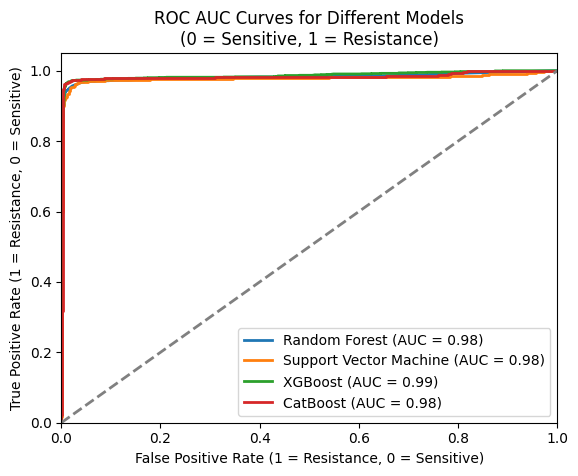

In [25]:
for model_name, model in best_models:
    print(f"\nTraining and evaluating {model_name}...")

    # Measure the training time
    start_time = time.time()  # Start the timer
    model.fit(feature, target)  # Train the model
    end_time = time.time()  # End the timer

    # Calculate and store the training time
    training_time = end_time - start_time
    best_ml_model_training_times[model_name] = training_time
    print(f"{model_name} took {training_time:.2f} seconds to train.")

    # Get cross-validated predictions (probabilities and class labels)
    y_pred_prob = None
    if hasattr(model, 'predict_proba'):
        y_pred_prob = cross_val_predict(model, feature, target, cv=5, method='predict_proba')[:, 1]

    # Get class predictions using cross_val_predict
    y_pred = cross_val_predict(model, feature, target, cv=5)

    # Calculate metrics and store them in final_model_metrics
    calculate_metrics(target, y_pred, model_name, y_pred_prob)

    # Compute ROC curve and AUC if probabilities are available
    if y_pred_prob is not None:
        fpr, tpr, thresholds = roc_curve(target, y_pred_prob)
        roc_auc = auc(fpr, tpr)

        # Plot ROC curve
        plt.plot(fpr, tpr, lw=2, label=f'{model_name} (AUC = {roc_auc:.2f})')

# Plot the diagonal line representing random guessing
plt.plot([0, 1], [0, 1], color='gray', linestyle='--', lw=2)

# Set plot limits and labels
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 = Resistance, 0 = Sensitive)')
plt.ylabel('True Positive Rate (1 = Resistance, 0 = Sensitive)')
plt.title('ROC AUC Curves for Different Models\n(0 = Sensitive, 1 = Resistance)')
plt.legend(loc="lower right")
plt.show()

In [26]:
df_best_ml_model_metrics=pd.DataFrame(best_ml_model_metrics)
df_best_ml_model_metrics.to_excel('cip_best_ml_model_metrics.xlsx', index=False)
print(df_best_ml_model_metrics)

                    model  accuracy  balanced_accuracy  precision    recall  \
0           Random Forest  0.970420           0.969982   0.987805  0.951174   
1  Support Vector Machine  0.964685           0.964251   0.981398  0.945612   
2                 XGBoost  0.976155           0.975896   0.986102  0.964771   
3           Random Forest  0.966496           0.966049   0.983943  0.946848   
4  Support Vector Machine  0.964685           0.964251   0.981398  0.945612   
5                 XGBoost  0.976155           0.975896   0.986102  0.964771   
6                CatBoost  0.977664           0.977357   0.989848  0.964153   

   f1_score       mcc     kappa          confusion_matrix  \
0  0.969144  0.941377  0.940757  [[1676, 19], [79, 1539]]   
1  0.963173  0.929864  0.929272  [[1666, 29], [88, 1530]]   
2  0.975320  0.952473  0.952260  [[1673, 22], [57, 1561]]   
3  0.965039  0.933533  0.932898  [[1670, 25], [86, 1532]]   
4  0.963173  0.929864  0.929272  [[1666, 29], [88, 1530]]   
5

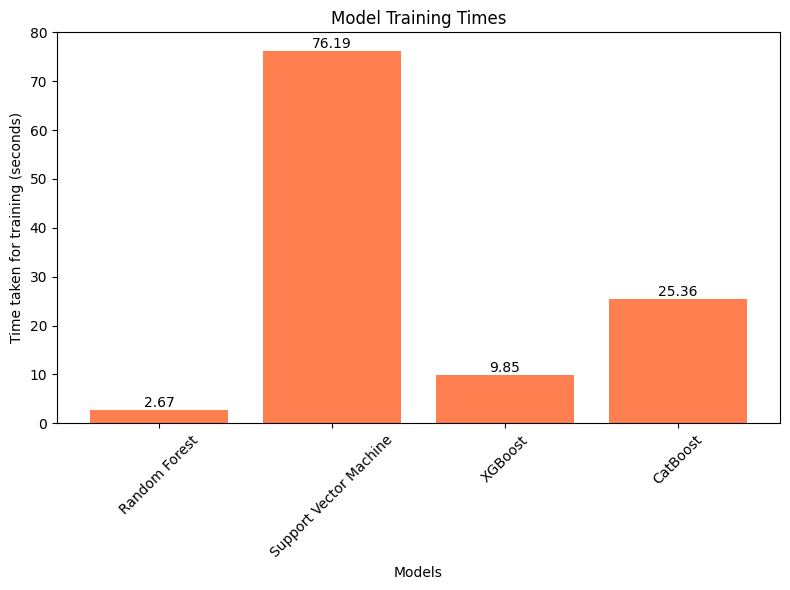

In [27]:
import matplotlib.pyplot as plt

# Assuming best_ml_model_training_times is a dictionary with model names as keys and training times as values
model_names = list(best_ml_model_training_times.keys())
training_times = list(best_ml_model_training_times.values())

plt.figure(figsize=(8, 6))

# Plot bar chart with coral color
bars = plt.bar(model_names, training_times, color='coral')

# Add value labels on top of each bar
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval, round(yval, 2), ha='center', va='bottom')

# Add titles and labels
plt.title('Model Training Times')
plt.xlabel('Models')
plt.ylabel('Time taken for training (seconds)')
plt.xticks(rotation=45)

# Show plot
plt.tight_layout()
plt.show()

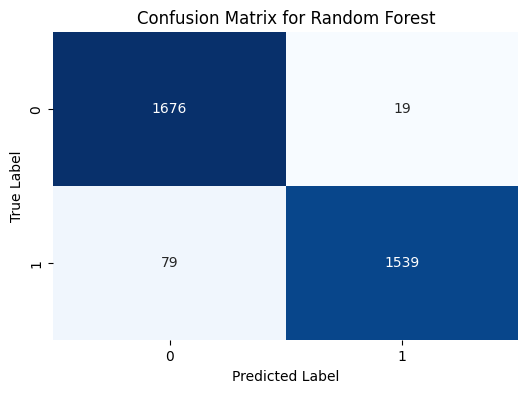

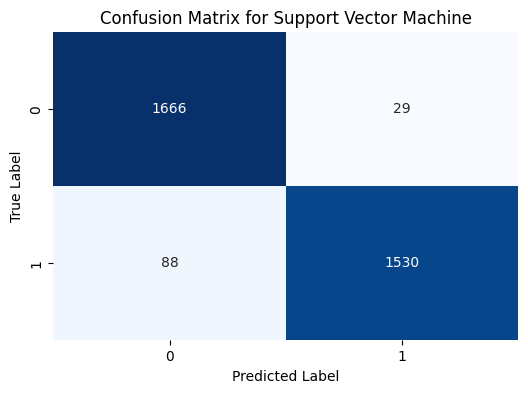

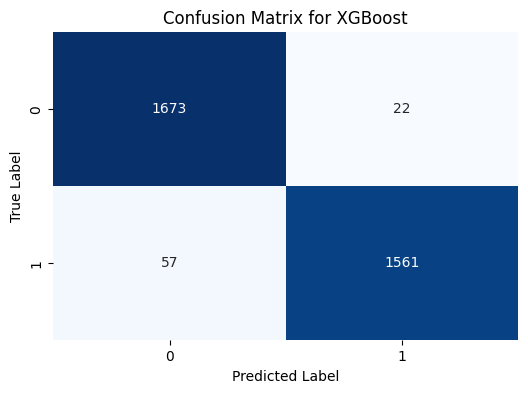

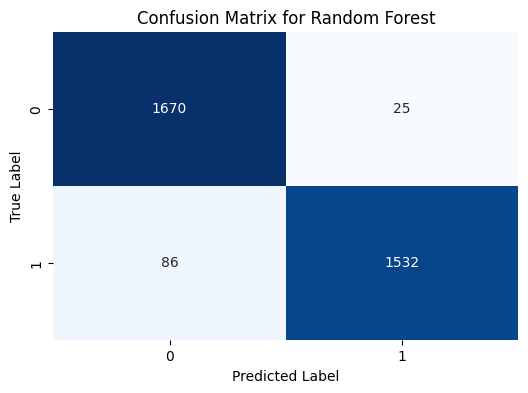

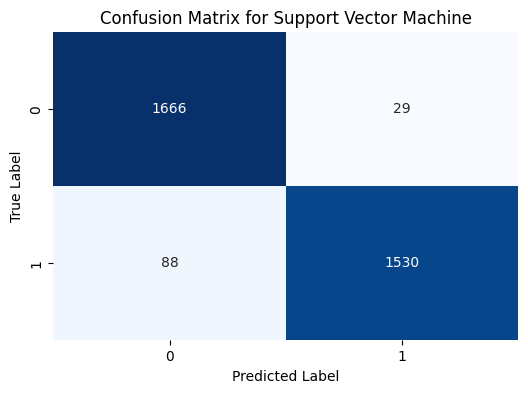

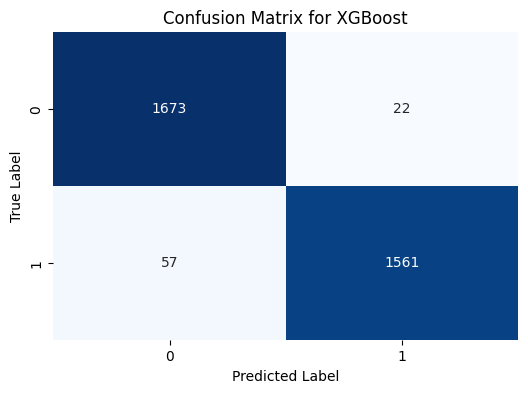

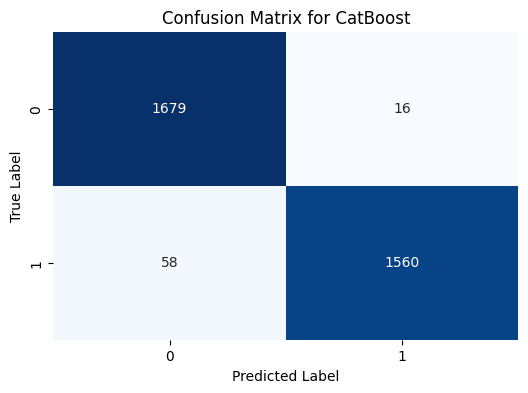

In [28]:
import seaborn as sns
def plot_confusion_matrix(conf_matrix, model_name):
    plt.figure(figsize=(6, 4))
    sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues", cbar=False)
    plt.title(f'Confusion Matrix for {model_name}')
    plt.ylabel('True Label')
    plt.xlabel('Predicted Label')
    plt.show()

# Loop through the final_model_metrics and plot the confusion matrix for each model
for metrics in best_ml_model_metrics:
    model_name = metrics['model']
    conf_matrix = metrics['confusion_matrix']
    plot_confusion_matrix(conf_matrix, model_name)

# Feature extraction

Top 10 Features for RandomForestClassifier:
GCGCAGCCGCAAATCTTGTTTTCCCATTCCGCC: 0.0182
GTGCGACAGCAAAGTCCAAACCAGCGTCCCCGCC: 0.0166
GACTACATCAGCGGCAACATCTTGTTTATGCTGACCG: 0.0147
CAGCTTGTGCAAAAGCTGCAAATACATCGGC: 0.0139
AATGGAAGCCCAACGCGCACGCGCACGCGCCGC: 0.0135
TGCCGCAGCAGAACCTAAAGCCGAGGAAAAAGCCGC: 0.0125
GCCGATTTGACACAGCTTGCGGGCATAACAGC: 0.0116
CAGGCGGAAATATAGTGGATTAAATTTAAAC: 0.0111
CACCCGACGACAGCGTGGGCAAAATCATCCG: 0.0110
AAATTGCGGATCGATGCGCGAAGGGTCGAATGC: 0.0109


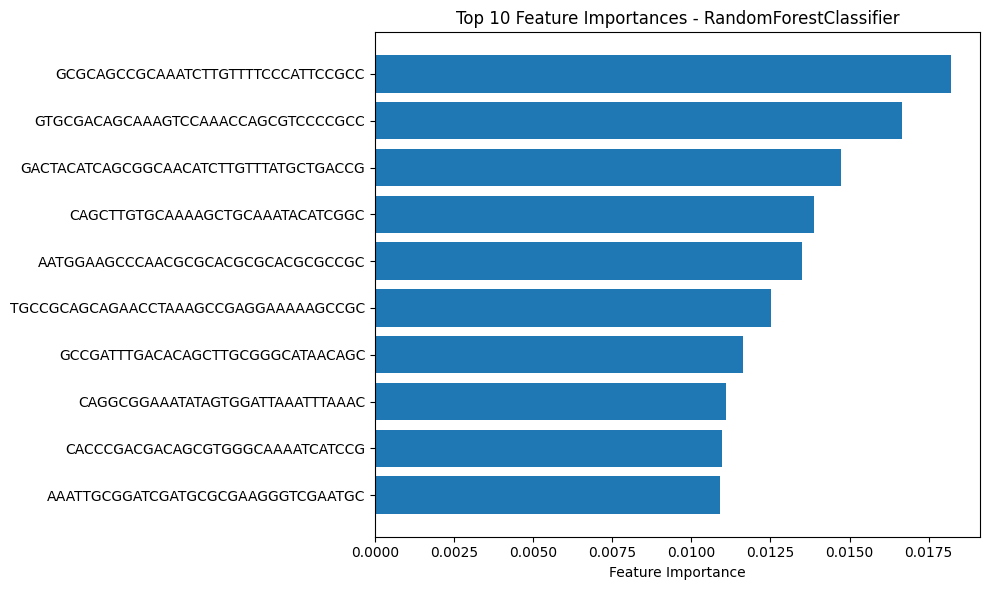

In [29]:
# Assuming you have already trained the model
# Example for a RandomForest model
model = RandomForestClassifier()  # Example: replace with the actual trained model
model.fit(feature, target)  # Train the model

# Check if the model supports feature importance
if hasattr(model, 'feature_importances_'):
    # Get feature importance
    feature_importance = model.feature_importances_

    # Assuming you have a list of feature names from your dataset
    feature_names = feature.columns  # If 'feature' is your training DataFrame

    # Sort feature importance in descending order
    indices = np.argsort(feature_importance)[::-1]
    sorted_features = np.array(feature_names)[indices]
    sorted_importance = feature_importance[indices]

    # Select the top 10 most important features
    top_10_features = sorted_features[:10]
    top_10_importance = sorted_importance[:10]

    # Print the top 10 features and their importance values
    print(f"Top 10 Features for {model.__class__.__name__}:")
    for feature, importance in zip(top_10_features, top_10_importance):
        print(f"{feature}: {importance:.4f}")

    # Plot the top 10 feature importance
    plt.figure(figsize=(10, 6))
    plt.title(f"Top 10 Feature Importances - {model.__class__.__name__}")
    plt.barh(range(len(top_10_importance)), top_10_importance, align="center")
    plt.yticks(range(len(top_10_importance)), top_10_features)
    plt.gca().invert_yaxis()  # To display the most important feature at the top
    plt.xlabel('Feature Importance')
    plt.tight_layout()
    plt.show()

else:
    print(f"Model {model.__class__.__name__} does not support feature importance extraction.")

In [37]:
target1=target
feature1=feature

Top 10 Features for XGBClassifier:
GCGCAGCCGCAAATCTTGTTTTCCCATTCCGCC: 0.2250
AAACCGTTTGCTTGGTAAGGGCTTTCTTAAATTTGA: 0.0335
ATCCGTGTCCGCGTGCAATACCTGCGGCACATTGACCATGTCAAACAG: 0.0189
GTGCGACAGCAAAGTCCAAACCAGCGTCCCCGCC: 0.0176
TACGATGCGCACGACTTTGCGCTCCACCGGC: 0.0166
AAAGAGCTTGAGGCTTTGGCGTGTGCGGCATCGGCTTGGA: 0.0161
TGTGTCCTAATTAACTGCTTTTCAAACCCGCCAAAA: 0.0147
CAAAAACGGCGAAAAAGGCCACGGTTCCGAC: 0.0129
CCGCGACAAAGCCACACAAGCCATCCTGCCCCTGCGCGGCAAAGTGCTCAATAG: 0.0113
TCAAAGGGAACGGTTCCCTAAGGCGCCCAAA: 0.0112


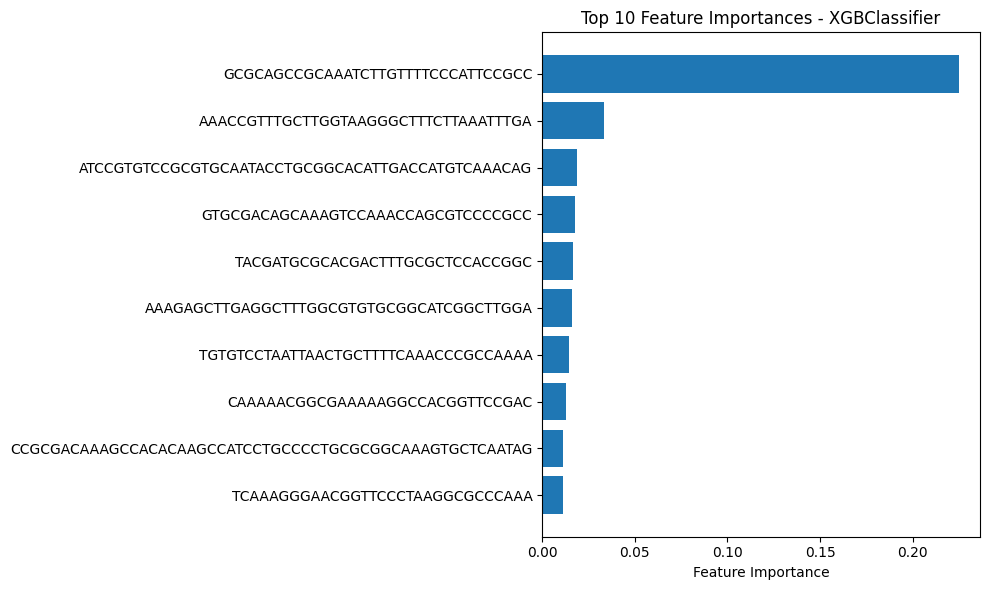

In [33]:
model = XGBClassifier(use_label_encoder=False, eval_metric='logloss')  # Example: replace with the actual trained model
model.fit(feature1, target1)  # Train the model

# Check if the model supports feature importance
if hasattr(model, 'feature_importances_'):
    # Get feature importance
    feature_importance = model.feature_importances_

    # Assuming you have a list of feature names from your dataset
    feature_names = feature.columns  # If 'feature' is your training DataFrame

    # Sort feature importance in descending order
    indices = np.argsort(feature_importance)[::-1]
    sorted_features = np.array(feature_names)[indices]
    sorted_importance = feature_importance[indices]

    # Select the top 10 most important features
    top_10_features = sorted_features[:10]
    top_10_importance = sorted_importance[:10]

    # Print the top 10 features and their importance values
    print(f"Top 10 Features for {model.__class__.__name__}:")
    for feature, importance in zip(top_10_features, top_10_importance):
        print(f"{feature}: {importance:.4f}")

    # Plot the top 10 feature importance
    plt.figure(figsize=(10, 6))
    plt.title(f"Top 10 Feature Importances - {model.__class__.__name__}")
    plt.barh(range(len(top_10_importance)), top_10_importance, align="center")
    plt.yticks(range(len(top_10_importance)), top_10_features)
    plt.gca().invert_yaxis()  # To display the most important feature at the top
    plt.xlabel('Feature Importance')
    plt.tight_layout()
    plt.show()

else:
    print(f"Model {model.__class__.__name__} does not support feature importance extraction.")

Top 10 Features for CatBoostClassifier:
GCGCAGCCGCAAATCTTGTTTTCCCATTCCGCC: 54.8853
GTGCGACAGCAAAGTCCAAACCAGCGTCCCCGCC: 14.7601
CAGCTTGTGCAAAAGCTGCAAATACATCGGC: 0.8225
TCGAACGCTACCGCGTCCAATCCGCCGGCGAC: 0.8031
GCAAATTTACGACGAACCCGAATTCGATCCTCAAGAGCTGCAAT: 0.7107
TTTGCATCCAGCGAAACCAAAGCCCCCTGCAGCAACGGCTCTTGAAC: 0.7102
CCGCGACAAAGCCACACAAGCCATCCTGCCCCTGCGCGGCAAAGTGCTCAATAG: 0.5438
CTGCCAAAAATCTGCTTAAAACATTTACGACC: 0.4801
AACCCGAATTCGATCCTCAAGAGCTGCAATCGGAGTATTACCGCGGT: 0.4126
GTGATGGGCAGAAGCAGGCAGAAGAGGGCGAGGCTG: 0.3861


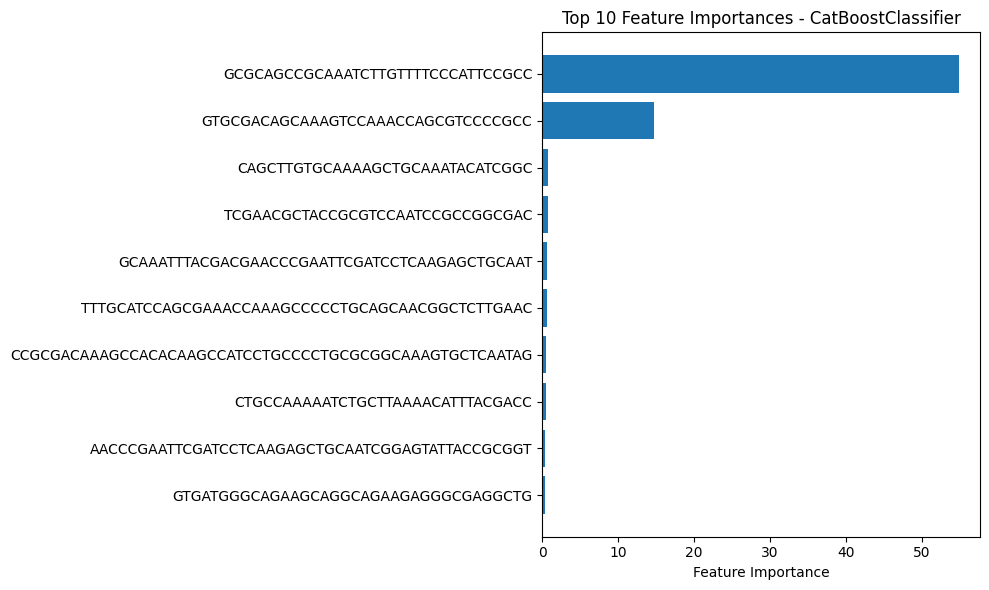

In [41]:
model = CatBoostClassifier(task_type='GPU', verbose=0)  # Example: replace with the actual trained model
model.fit(feature, target)  # Train the model

# Check if the model supports feature importance
if hasattr(model, 'feature_importances_'):
    # Get feature importance
    feature_importance = model.feature_importances_

    # Assuming you have a list of feature names from your dataset
    feature_names = feature.columns  # If 'feature' is your training DataFrame

    # Sort feature importance in descending order
    indices = np.argsort(feature_importance)[::-1]
    sorted_features = np.array(feature_names)[indices]
    sorted_importance = feature_importance[indices]

    # Select the top 10 most important features
    top_10_features = sorted_features[:10]
    top_10_importance = sorted_importance[:10]

    # Print the top 10 features and their importance values
    print(f"Top 10 Features for {model.__class__.__name__}:")
    for feature, importance in zip(top_10_features, top_10_importance):
        print(f"{feature}: {importance:.4f}")

    # Plot the top 10 feature importance
    plt.figure(figsize=(10, 6))
    plt.title(f"Top 10 Feature Importances - {model.__class__.__name__}")
    plt.barh(range(len(top_10_importance)), top_10_importance, align="center")
    plt.yticks(range(len(top_10_importance)), top_10_features)
    plt.gca().invert_yaxis()  # To display the most important feature at the top
    plt.xlabel('Feature Importance')
    plt.tight_layout()
    plt.show()

else:
    print(f"Model {model.__class__.__name__} does not support feature importance extraction.")


Top 5 Positive Features:
ATGCAGTTCTCGGCATTCGGCGAAAAATTCACGCAACAC: 0.2693
GCCTATTACAGGACAGTGCCTTTGCGGTAAAAGA: 0.2597
GGAGACGAAGCCGCAGACAGCAGGGCAAGGCGGGG: 0.2398
GAAGGCAAAGGGCGTTATGTGATTGTTTCGGT: 0.2336
CAGGCGGAAATATAGTGGATTAAATTTAAAC: 0.2250

Top 5 Negative Features:
GCGCAGCCGCAAATCTTGTTTTCCCATTCCGCC: -0.5231
CGCCCTGCCGCCCATTTTCAGCCAGTTTTCC: -0.4202
CCGTCTGAAACCGCATGACCTCCCTGATTCACA: -0.4159
TGGTCAGATTTGAATTTAATGCCCGCACTGCCCGAA: -0.4111
CATCTTTTTCGGGCAATACGCTGAAATTGCGCG: -0.3641


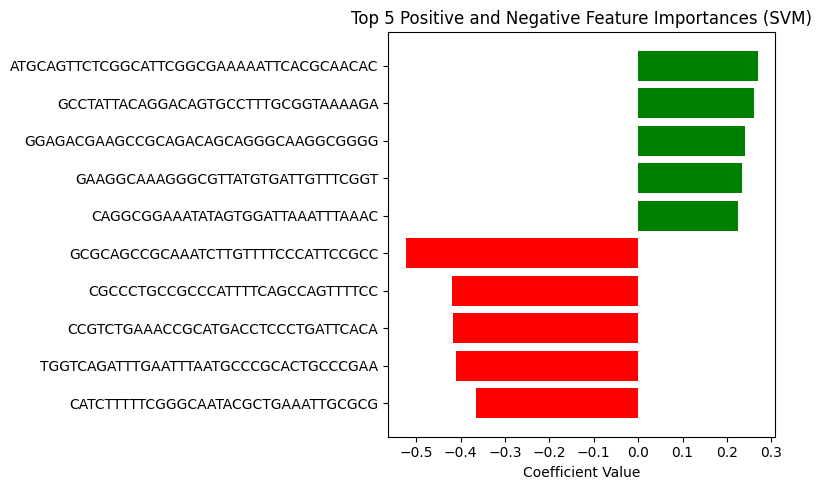

In [44]:
# Assuming your trained SVM model and feature data are ready
model = SVC(kernel='linear')  # Use a linear kernel for SVM
model.fit(feature, target)  # Fit the model with your feature data and target labels

# Extract feature names
feature_names = feature.columns  # Assuming 'feature' is a DataFrame

# Extract the coefficients (weights) from the trained linear SVC model
coef = model.coef_[0]  # SVC returns a 2D array, use [0] for binary classification

# Sort the coefficients to get the top positive and top negative features
top_n = 5  # Number of top positive and negative features

# Top N positive coefficients
top_positive_indices = np.argsort(coef)[::-1][:top_n]
top_positive_features = np.array(feature_names)[top_positive_indices]
top_positive_importance = coef[top_positive_indices]

# Top N negative coefficients
top_negative_indices = np.argsort(coef)[:top_n]
top_negative_features = np.array(feature_names)[top_negative_indices]
top_negative_importance = coef[top_negative_indices]

# Print top positive features
print(f"\nTop {top_n} Positive Features:")
for feature, importance in zip(top_positive_features, top_positive_importance):
    print(f"{feature}: {importance:.4f}")

# Print top negative features
print(f"\nTop {top_n} Negative Features:")
for feature, importance in zip(top_negative_features, top_negative_importance):
    print(f"{feature}: {importance:.4f}")

# Combine top positive and negative features for plotting
combined_features = np.concatenate([top_positive_features, top_negative_features])
combined_importance = np.concatenate([top_positive_importance, top_negative_importance])

# Plot top positive and negative feature importances
plt.figure(figsize=(8, 5))
plt.barh(range(2*top_n), combined_importance, align="center", color=['green']*top_n + ['red']*top_n)
plt.yticks(range(2*top_n), combined_features)
plt.gca().invert_yaxis()  # To display the most important feature at the top
plt.xlabel('Coefficient Value')
plt.title(f'Top {top_n} Positive and Negative Feature Importances (SVM)')
plt.tight_layout()
plt.show()

# grid search

In [46]:
# gridseasrch based model
performance = []
method = []
times = []
scores=[]

def fitmodel(X, pheno, estimator, parameters, modelname, method, performance, times) :

    kfold = KFold(n_splits=5)
    kfold_id = 0
    for train_index, test_index in kfold.split(X, pheno):
        # time how long it takes to train each model type
        start = time.process_time()

        # split data into train/test sets
        X_train = X.iloc[train_index]
        y_train = pheno[train_index]
        X_test = X.iloc[test_index]
        y_test = pheno[test_index]

        # perform grid search to identify best hyper-parameters
        gs_clf = GridSearchCV(estimator=estimator, param_grid=parameters, cv=3, n_jobs=-1, scoring='balanced_accuracy')
        gs_clf.fit(X_train, y_train)

        # predict resistance in test set
        y_pred = gs_clf.predict(X_test)
        y_pred_prob = gs_clf.predict_proba(X_test)[:, 1]

        # call all samples with a predicted value less than or equal to 0.5 as sensitive to the antibiotic,
        # and samples with predicted value >0.5 resistant to the antibiotic
        y_pred[y_pred<=0.5] = 0
        y_pred[y_pred>0.5] = 1

        # Calculate performance metrics
        accuracy = accuracy_score(y_test, y_pred)
        balance_accuracy = balanced_accuracy_score(y_test, y_pred)
        precision = precision_score(y_test, y_pred)
        recall = recall_score(y_test, y_pred)
        f1 = f1_score(y_test, y_pred)
        mcc = matthews_corrcoef(y_test, y_pred)
        kappa = cohen_kappa_score(y_test, y_pred)
        auc_roc = roc_auc_score(y_test, y_pred_prob)
        confusionMatrix = confusion_matrix(y_test, y_pred)
        classificationReport = classification_report(y_test, y_pred)

        # Store performance metrics for later analysis
        performance = np.append(performance, balance_accuracy)
        method = np.append(method, modelname)
        times = np.append(times, (time.process_time() - start))

        # Append metrics to the scores list
        scores.append({
            'model': modelname,
            'fold': kfold_id,
            'accuracy': accuracy,
            'balanced_accuracy': balance_accuracy,
            'precision': precision,
            'recall': recall,
            'f1': f1,
            'mcc': mcc,
            'kappa': kappa,
            'roc_auc': auc_roc,
            'confusion_matrix': confusionMatrix,
            'classification_report': classificationReport
        })
        print(f'\n{modelname} kfold={kfold_id}')
        print(f'{gs_clf.best_params_}')
        print(f'balance acuracy={balance_accuracy}')
        print("Confusion matrix")
        print(confusionMatrix)
        print('classification_report')
        print(classificationReport)
        kfold_id=kfold_id+1
    print(f'----end {modelname} -------')
    return gs_clf, method, performance, times, scores

In [49]:
#grid search fit model and its performance
svm = SVC(class_weight='balanced', probability=True)
svm_params = {
    'C': [0.01],
    'gamma': [1e-06, 1e-05],
    'kernel': ['linear', 'rbf', 'sigmoid'],
    'class_weight': ['balanced']
}

svm_model, method, performance, times, scores = fitmodel(feature, target, svm, svm_params, "Support vector machine", method, performance, times)


Support vector machine kfold=0
{'C': 0.01, 'class_weight': 'balanced', 'gamma': 1e-06, 'kernel': 'linear'}
balance acuracy=0.9887865715391848
Confusion matrix
[[367   2]
 [  5 289]]
classification_report
              precision    recall  f1-score   support

           0       0.99      0.99      0.99       369
           1       0.99      0.98      0.99       294

    accuracy                           0.99       663
   macro avg       0.99      0.99      0.99       663
weighted avg       0.99      0.99      0.99       663


Support vector machine kfold=1
{'C': 0.01, 'class_weight': 'balanced', 'gamma': 1e-06, 'kernel': 'linear'}
balance acuracy=0.9820060207991242
Confusion matrix
[[341   7]
 [  5 310]]
classification_report
              precision    recall  f1-score   support

           0       0.99      0.98      0.98       348
           1       0.98      0.98      0.98       315

    accuracy                           0.98       663
   macro avg       0.98      0.98      0.98  

# DEEP Learning

In [ ]:
import tensorflow as tf
from sklearn.model_selection import KFold
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.layers import GRU
from tensorflow.keras.optimizers import Adam
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.layers import Dense, Dropout, Conv1D, Flatten

In [ ]:
def create_mlp(input_shape):
    model = Sequential()
    model.add(Dense(128, activation='relu', input_shape=(input_shape,)))
    model.add(Dropout(0.5))
    model.add(Dense(64, activation='relu'))
    model.add(Dense(1, activation='sigmoid'))
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    return model

def create_cnn(input_shape):
    model = Sequential()
    model.add(Conv1D(32, 3, activation='relu', input_shape=(input_shape, 1)))
    model.add(Flatten())
    model.add(Dense(64, activation='relu'))
    model.add(Dense(1, activation='sigmoid'))
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    return model

def create_rnn(input_shape):
    model = Sequential()
    model.add(GRU(64, input_shape=input_shape))
    model.add(Dense(1, activation='sigmoid'))
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    return model

In [ ]:
# Scale the features (X_train) and reshape if needed for CNN/RNN
scaler = StandardScaler()
X_scaled = scaler.fit_transform(feature)

# Add a dimension for CNN and RNN models (they expect 3D input: samples, time steps, features)
X_scaled_reshaped = X_scaled.reshape((X_scaled.shape[0], X_scaled.shape[1], 1))

In [ ]:
X_scaled_reshaped.shape

(3313, 8873, 1)

# calculating matrix

In [ ]:
#deep learning model prfomance score
dp_scores = []

In [ ]:
#performance score function store to dp_score array
def calculate_metrics(y_test, y_pred, model_name, fold, y_pred_prob=None):
    metrics = {
        'model': model_name,
        'fold': fold+1,
        'accuracy': accuracy_score(y_test, y_pred),
        'balanced_accuracy': balanced_accuracy_score(y_test, y_pred),
        'precision': precision_score(y_test, y_pred),
        'recall': recall_score(y_test, y_pred),
        'f1_score': f1_score(y_test, y_pred),
        'mcc': matthews_corrcoef(y_test, y_pred),
        'kappa': cohen_kappa_score(y_test, y_pred),
        'confusion_matrix': confusion_matrix(y_test, y_pred),
        'classification_report': classification_report(y_test, y_pred, output_dict=True)
    }

    # AUC-ROC is only calculated if probability predictions are available
    if y_pred_prob is not None:
        metrics['auc_roc'] = roc_auc_score(y_test, y_pred_prob)


    return metrics

In [ ]:
#train fit model function
def evaluate_deep_learning_model(model_name, model, X_train_fold, X_test_fold, y_train_fold, y_test_fold, fold):
    # Train the model
    model.fit(X_train_fold, y_train_fold, epochs=50, batch_size=32, verbose=0)

    # Predict the labels and probabilities
    y_pred = (model.predict(X_test_fold) > 0.5).astype("int32")
    y_pred_prob = model.predict(X_test_fold) # Extract probabilities if required

    # Calculate all the metrics
    fold_metrics = calculate_metrics(y_test_fold, y_pred, model_name, fold, y_pred_prob)
    dp_scores.append(fold_metrics)

# K fold traing

In [ ]:
#k-fold cross validation train function
kfold = KFold(n_splits=5, shuffle=True, random_state=42)

# Train and evaluate each model using KFold cross-validation
for fold, (train_index, test_index) in enumerate(kfold.split(X_scaled, target)):
    print(f"Training fold {fold + 1}...")
    y_train=target
    # Split the data into training and testing for this fold
    X_train_fold, X_test_fold = X_scaled[train_index], X_scaled[test_index]
    X_train_fold_rnn, X_test_fold_rnn = X_scaled_reshaped[train_index], X_scaled_reshaped[test_index]
    y_train_fold, y_test_fold = y_train.iloc[train_index], y_train.iloc[test_index]

    # MLP Model
    mlp_model = create_mlp(X_train_fold.shape[1])
    evaluate_deep_learning_model('MLP', mlp_model, X_train_fold, X_test_fold, y_train_fold, y_test_fold, fold)

    # CNN Model
    cnn_model = create_cnn(X_train_fold_rnn.shape[1])
    evaluate_deep_learning_model('CNN', cnn_model, X_train_fold_rnn, X_test_fold_rnn, y_train_fold, y_test_fold, fold)


Training fold 1...
21/21 ━━━━━━━━━━━━━━━━━━━━ 2s 42ms/step
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
Training fold 2...
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
Training fold 3...
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
Training fold 4...
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 44ms/step
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
Training fold 5...
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 


In [ ]:
df_dp_scores=pd.DataFrame(dp_scores)
print(df_dp_scores)

  model  fold  accuracy  balanced_accuracy  precision    recall  f1_score  \
0   MLP     1  0.951735           0.952814   0.931034  0.967427  0.948882   
1   CNN     1  0.963801           0.964499   0.949206  0.973941  0.961415   
2   MLP     2  0.966817           0.966527   0.956772  0.979351  0.967930   
3   CNN     2  0.975867           0.975855   0.976401  0.976401  0.976401   
4   MLP     3  0.962293           0.961966   0.974603  0.947531  0.960876   
5   CNN     3  0.960784           0.960355   0.977564  0.941358  0.959119   
6   MLP     4  0.974320           0.974543   0.966154  0.981250  0.973643   
7   CNN     4  0.977341           0.977166   0.981073  0.971875  0.976452   
8   MLP     5  0.975831           0.975829   0.975610  0.975610  0.975610   
9   CNN     5  0.978852           0.978795   0.984568  0.972561  0.978528   

        mcc     kappa        confusion_matrix  \
0  0.903795  0.903199  [[334, 22], [10, 297]]   
1  0.927607  0.927335   [[340, 16], [8, 299]]   
2  0.

In [ ]:
df_dp_scores.to_excel('output.xlsx', index=False)

# best deep model

In [ ]:
#best function model retrain
best_cnn_model = create_cnn(X_scaled.shape[1])

# Train on the entire dataset
mlp_best_estimators = best_cnn_model.fit(X_scaled, target, validation_split=0.2, epochs=50, batch_size=32, verbose=0)

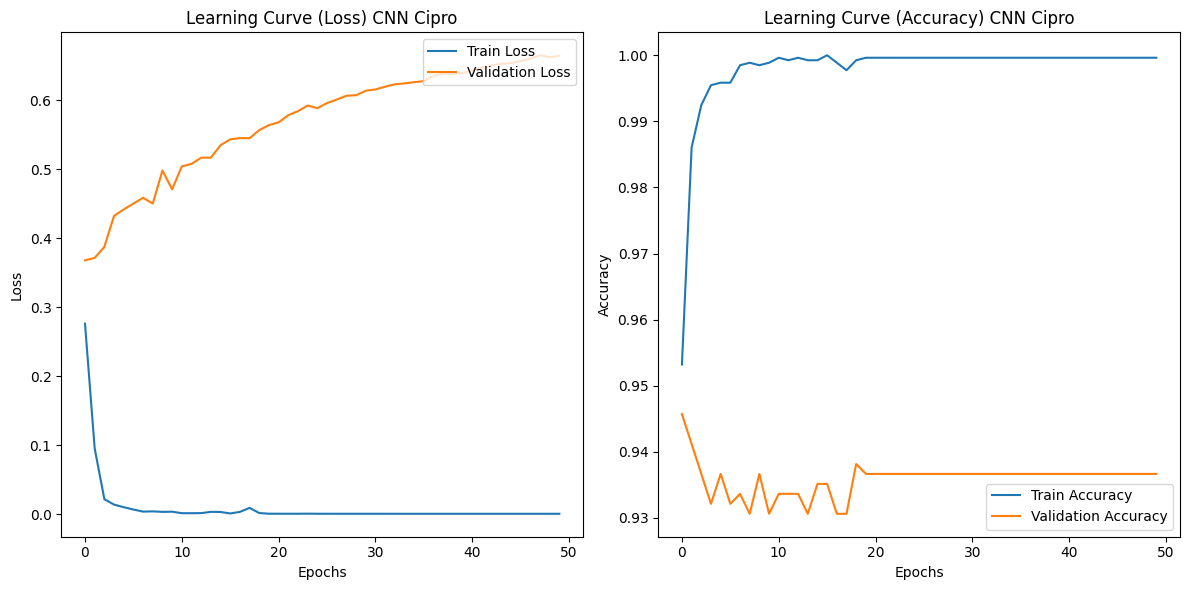

In [ ]:

import matplotlib.pyplot as plt

# Access the history from the training process
history = mlp_best_estimators  # This holds the training history

# Plot the learning curves for loss
plt.figure(figsize=(12, 6))

# Plot training & validation loss values
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Learning Curve (Loss) CNN Cipro')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend(loc='upper right')

# Plot training & validation accuracy values
plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Learning Curve (Accuracy) CNN Cipro')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend(loc='lower right')

# Adjust layout and show the plots
plt.tight_layout()
plt.show()

21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step


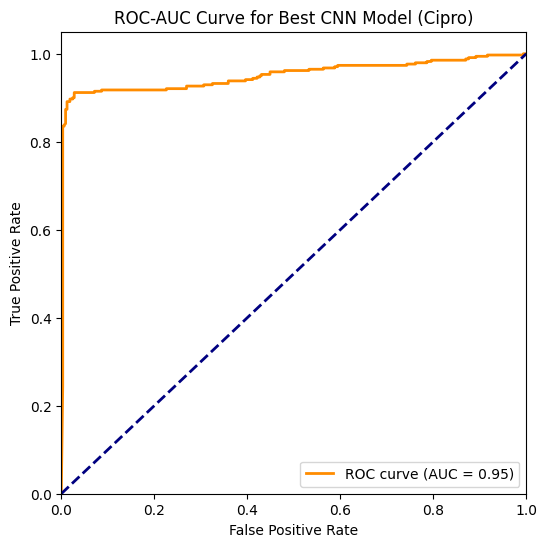

In [ ]:
# Compute the ROC curve
# Predict the probabilities and labels on the validation set

# Use the last 20% of the dataset as the validation set (based on the validation_split)
X_val = X_scaled[int(0.8 * len(X_scaled)):]
y_val = target[int(0.8 * len(target)):]
y_pred_prob = best_cnn_model.predict(X_val)
y_pred = (y_pred_prob > 0.5).astype("int32")
fpr, tpr, _ = roc_curve(y_val, y_pred_prob)

# Calculate the AUC (Area Under the Curve)
roc_auc = auc(fpr, tpr)

# Plot the ROC curve
plt.figure(figsize=(6, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')  # Diagonal line (random guessing)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC-AUC Curve for Best CNN Model (Cipro)')
plt.legend(loc='lower right')
plt.show()

# best deep model perfomance

In [ ]:
# Calculate evaluation metrics
accuracy = accuracy_score(y_val, y_pred)
balanced_accuracy = balanced_accuracy_score(y_val, y_pred)
precision = precision_score(y_val, y_pred)
recall = recall_score(y_val, y_pred)
f1 = f1_score(y_val, y_pred)
mcc = matthews_corrcoef(y_val, y_pred)
kappa = cohen_kappa_score(y_val, y_pred)
auc_roc = roc_auc_score(y_val, y_pred_prob)
conf_matrix = confusion_matrix(y_val, y_pred)
class_report = classification_report(y_val, y_pred)

# Print out the evaluation metrics
print(f"Accuracy: {accuracy:.4f}")
print(f"Balanced Accuracy: {balanced_accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-Score: {f1:.4f}")
print(f"MCC (Matthews Correlation Coefficient): {mcc:.4f}")
print(f"Cohen's Kappa: {kappa:.4f}")
print(f"AUC-ROC: {auc_roc:.4f}")
print("\nConfusion Matrix:")
print(conf_matrix)
print("\nClassification Report:")
print(class_report)

Accuracy: 0.9367
Balanced Accuracy: 0.9373
Precision: 0.9627
Recall: 0.9118
F1-Score: 0.9366
MCC (Matthews Correlation Coefficient): 0.8747
Cohen's Kappa: 0.8734
AUC-ROC: 0.9507

Confusion Matrix:
[[311  12]
 [ 30 310]]

Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.96      0.94       323
           1       0.96      0.91      0.94       340

    accuracy                           0.94       663
   macro avg       0.94      0.94      0.94       663
weighted avg       0.94      0.94      0.94       663

